# 03. Первое работающее решение
## Третья неделя

**Автор / команда:** Сипко Максим Юрьевич, Мурашов Никита Александрович, группа КМБО-23-24  
**Проект:** Система распознавания эмоций покупателей в торговых точках  
**Данные:** FER-2013, подготовленные на второй неделе.

Цель этой работы — получить первый воспроизводимый baseline. Используется одна CNN без перебора гиперпараметров. Обучение выполняется только на `train`, выбор метрик и просмотр ошибок — на `validation`. `test.npz` на этой неделе намеренно не загружается.

## 1. Выбор базового подхода

**Задача:** по одному изображению лица размером 48×48 в оттенках серого предсказать один из семи классов: `angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, `surprise`.

**Подход:** небольшая сверточная нейронная сеть (CNN), обучаемая с нуля. Свёрточные слои подходят для изображений, поскольку извлекают локальные визуальные признаки и сохраняют пространственную структуру кадра. На вход подаётся тензор `(48, 48, 1)` с пикселями в диапазоне `[0, 1]`; на выходе — вероятности семи классов и класс с максимальной вероятностью.

**Фиксированные настройки baseline:** Adam, learning rate `0.001`, batch size `64`, до `20` эпох, `EarlyStopping` по `val_loss` с patience `4`. Для обучения используются веса классов, рассчитанные только по `y_train`. Аугментация применяется только к train: горизонтальное отражение, небольшой поворот и сдвиг. Это один стартовый вариант, а не подбор лучшей архитектуры.

In [1]:
from pathlib import Path
import json, os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
EMOTION_RU = {
    'angry':'злость', 'disgust':'отвращение', 'fear':'страх',
    'happy':'радость', 'neutral':'нейтральное', 'sad':'грусть',
    'surprise':'удивление'
}
OUTPUT_DIR = Path('/kaggle/working/week3_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = OUTPUT_DIR / 'baseline_model'
MODEL_DIR.mkdir(exist_ok=True)
print('TensorFlow:', tf.__version__)
print('Результаты будут сохранены в:', OUTPUT_DIR)

I0000 00:00:1795691200.312608      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795691218.657634      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
Результаты будут сохранены в: /kaggle/working/week3_output


## 2. Загрузка данных и проверка формата

Подключите к Kaggle Notebook Dataset с результатами второй недели — папкой `prepared_fer2013`, содержащей `train.npz`, `val.npz`, `class_weights.json` и `label_map.json`. Самый простой способ — в первой неделе/ноутбуке подготовки сохранить папку как Kaggle Dataset, затем добавить его через **Add Input**.

Ищем файлы автоматически в `/kaggle/input`. Если папка находится в другом месте, укажите путь в `PREPARED_DIR`.

In [2]:
def find_prepared_dir():
    candidates = [Path('/kaggle/input'), Path('/kaggle/working'), Path('.')]
    for base in candidates:
        if base.exists():
            for p in base.rglob('train.npz'):
                if (p.parent / 'val.npz').exists() and (p.parent / 'class_weights.json').exists():
                    return p.parent
    raise FileNotFoundError(
        'Не найдены train.npz, val.npz и class_weights.json. '
        'Добавьте Kaggle Dataset с результатами второй недели через Add Input.'
    )

PREPARED_DIR = find_prepared_dir()  # при необходимости замените на Path('/kaggle/input/.../prepared_fer2013')
print('Папка подготовленных данных:', PREPARED_DIR)

with np.load(PREPARED_DIR / 'train.npz', allow_pickle=False) as d:
    X_train, y_train, train_ids = d['images'], d['labels'], d['image_ids']
with np.load(PREPARED_DIR / 'val.npz', allow_pickle=False) as d:
    X_val, y_val, val_ids = d['images'], d['labels'], d['image_ids']

class_weights_raw = json.loads((PREPARED_DIR / 'class_weights.json').read_text(encoding='utf-8'))
class_weights = {i: float(class_weights_raw[name]) for i, name in enumerate(EMOTIONS)}

assert X_train.ndim == 3 and X_train.shape[1:] == (48, 48)
assert X_val.ndim == 3 and X_val.shape[1:] == (48, 48)
assert len(X_train) == len(y_train) == len(train_ids)
assert len(X_val) == len(y_val) == len(val_ids)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_val.min() <= X_val.max() <= 1
assert set(np.unique(y_train)).issubset(set(range(7)))
assert set(np.unique(y_val)).issubset(set(range(7)))
assert set(train_ids).isdisjoint(set(val_ids))

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Пересечение ID train/validation:', len(set(train_ids) & set(val_ids)))
display(pd.DataFrame({
    'emotion': EMOTIONS,
    'train_count': np.bincount(y_train, minlength=7),
    'class_weight': [class_weights[i] for i in range(7)]
}))

Папка подготовленных данных: /kaggle/input/datasets/nathan13122005/02task-dataset/prepared_fer2013
Train: (22874, 48, 48) (22874,)
Validation: (4037, 48, 48) (4037,)
Пересечение ID train/validation: 0


,emotion,train_count,class_weight
0,angry,3210,1.017980
1,disgust,298,10.965484
2,fear,3227,1.012617
3,happy,5975,0.546898
4,neutral,4098,0.797392
5,sad,3975,0.822066
6,surprise,2091,1.562752


### Подготовка входа модели

Во второй неделе изображения уже нормализованы делением на 255 и имеют форму `(N, 48, 48)`. Поэтому повторно нормализацию не выполняем, только добавляем канал: `(N, 48, 48, 1)`. Порядок примеров и меток не меняется.

In [3]:
X_train_ready = X_train.astype('float32')[..., np.newaxis]
X_val_ready = X_val.astype('float32')[..., np.newaxis]
y_train = y_train.astype('int64')
y_val = y_val.astype('int64')

assert X_train_ready.shape == (len(y_train), 48, 48, 1)
assert X_val_ready.shape == (len(y_val), 48, 48, 1)
assert np.array_equal(X_train_ready[..., 0], X_train)
assert np.array_equal(X_val_ready[..., 0], X_val)
print('Формат модели:', X_train_ready.shape, X_val_ready.shape)

Формат модели: (22874, 48, 48, 1) (4037, 48, 48, 1)


## 3. Обучение baseline CNN

Архитектура: блоки `Conv2D + MaxPooling`, затем `GlobalAveragePooling`, полносвязный слой и `Softmax` на семь классов. Используем `EarlyStopping` и сохраняем веса лучшей эпохи по validation loss. Validation используется для контроля обучения, но не для обновления весов градиентом.

In [4]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.04, fill_mode='nearest'),
    tf.keras.layers.RandomTranslation(0.04, 0.04, fill_mode='nearest')
], name='train_augmentation')

inputs = tf.keras.Input(shape=(48, 48, 1), name='face_image')
x = augmentation(inputs)
x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.35)(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(7, activation='softmax', name='emotion_probabilities')(x)

model = tf.keras.Model(inputs, outputs, name='fer2013_baseline_cnn')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True, verbose=1
    )
]
history = model.fit(
    X_train_ready, y_train,
    validation_data=(X_val_ready, y_val),
    epochs=20,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

E0000 00:00:1795691236.187827      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "fer2013_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ face_image (InputLayer)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ train_augmentation (Sequential) │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_probabilities (Dense)   │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,983 (433.53 KB)

 Trainable params: 110,535 (431.78 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 82s 218ms/step - accuracy: 0.1925 - loss: 1.9406 - val_accuracy: 0.1078 - val_loss: 1.9946
Epoch 2/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 77s 216ms/step - accuracy: 0.2433 - loss: 1.8613 - val_accuracy: 0.3190 - val_loss: 1.7344
Epoch 3/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 79s 220ms/step - accuracy: 0.3002 - loss: 1.7710 - val_accuracy: 0.3079 - val_loss: 1.7179
Epoch 4/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 76s 211ms/step - accuracy: 0.3371 - loss: 1.6947 - val_accuracy: 0.2844 - val_loss: 1.9460
Epoch 5/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 74s 207ms/step - accuracy: 0.3691 - loss: 1.6186 - val_accuracy: 0.3820 - val_loss: 1.6108
Epoch 6/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 77s 214ms/step - accuracy: 0.3864 - loss: 1.5828 - val_accuracy: 0.3864 - val_loss: 1.5724
Epoch 7/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 79s 221ms/step - accuracy: 0.4038 - loss: 1.5269 - val_accuracy: 0.4295 - val_loss: 1.5212
Epoch 8/20
358/358 ━━━━━━━━━━━━━━━━━━━━ 90s 252ms/step - accuracy: 0.4202 - loss: 1

## 4. Предсказания на validation

Для каждого изображения получаем вероятности семи классов и выбираем класс с максимальной вероятностью. `test.npz` не используется.

In [5]:
val_probabilities = model.predict(X_val_ready, batch_size=128, verbose=1)
val_predictions = np.argmax(val_probabilities, axis=1)

assert val_predictions.shape == y_val.shape
assert val_probabilities.shape == (len(y_val), 7)
assert np.isfinite(val_probabilities).all()
assert np.allclose(val_probabilities.sum(axis=1), 1.0, atol=1e-4)
print('Предсказаний:', len(val_predictions))

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step
Предсказаний: 4037


## 5. Первые метрики на validation

Основные показатели: **Macro-F1** (одинаковый вес каждому классу при усреднении), accuracy, macro precision и macro recall. Также показываем recall для трёх отрицательных классов, но это не медицинская и не психологическая оценка.

,accuracy,macro_f1,macro_precision,macro_recall,negative_emotions_recall_macro
0,0.5133,0.448,0.4646,0.4728,0.3026


              precision    recall  f1-score   support

      злость     0.3602    0.5212    0.4260       566
  отвращение     0.1970    0.2500    0.2203        52
       страх     0.3652    0.2211    0.2754       570
     радость     0.8193    0.6749    0.7401      1055
 нейтральное     0.4342    0.6985    0.5355       723
      грусть     0.5169    0.2179    0.3066       702
   удивление     0.5595    0.7263    0.6321       369

    accuracy                         0.5133      4037
   macro avg     0.4646    0.4728    0.4480      4037
weighted avg     0.5375    0.5133    0.5019      4037



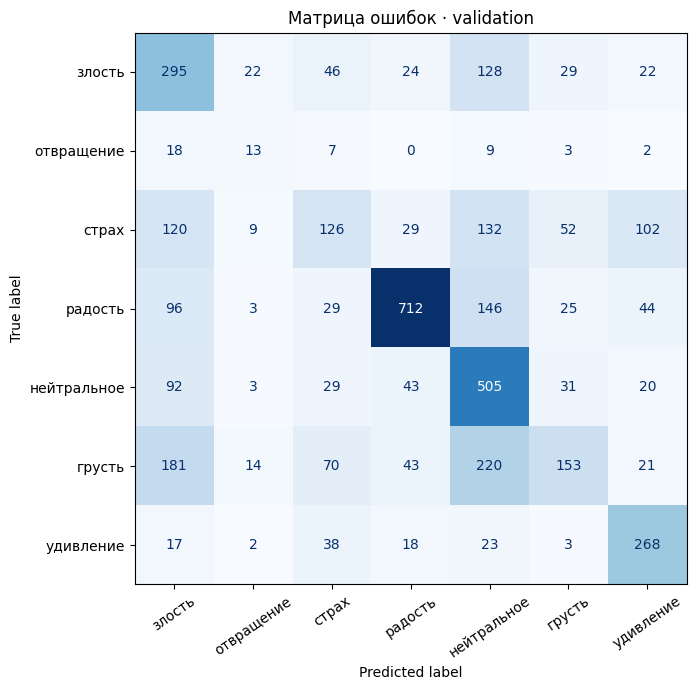

In [6]:
metrics = {
    'accuracy': float(accuracy_score(y_val, val_predictions)),
    'macro_f1': float(f1_score(y_val, val_predictions, average='macro', zero_division=0)),
    'macro_precision': float(precision_score(y_val, val_predictions, average='macro', zero_division=0)),
    'macro_recall': float(recall_score(y_val, val_predictions, average='macro', zero_division=0)),
    'negative_emotions_recall_macro': float(
        recall_score(y_val, val_predictions, labels=[0, 1, 2, 5], average='macro', zero_division=0)
    )
}
display(pd.DataFrame([metrics]).round(4))
print(classification_report(
    y_val, val_predictions, labels=list(range(7)),
    target_names=[EMOTION_RU[e] for e in EMOTIONS],
    zero_division=0, digits=4
))
(OUTPUT_DIR / 'metrics.json').write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8'
)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix(y_val, val_predictions),
    display_labels=[EMOTION_RU[e] for e in EMOTIONS]
).plot(ax=ax, cmap='Blues', xticks_rotation=35, colorbar=False)
ax.set_title('Матрица ошибок · validation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Примеры правильных и ошибочных предсказаний

Показываем реальные изображения из validation, истинный класс, предсказанный класс и уверенность модели. ID сохраняется в CSV. Причины ошибок не предполагаем — только фиксируем наблюдаемую путаницу.

Верных примеров: 2072 | Ошибочных: 1965


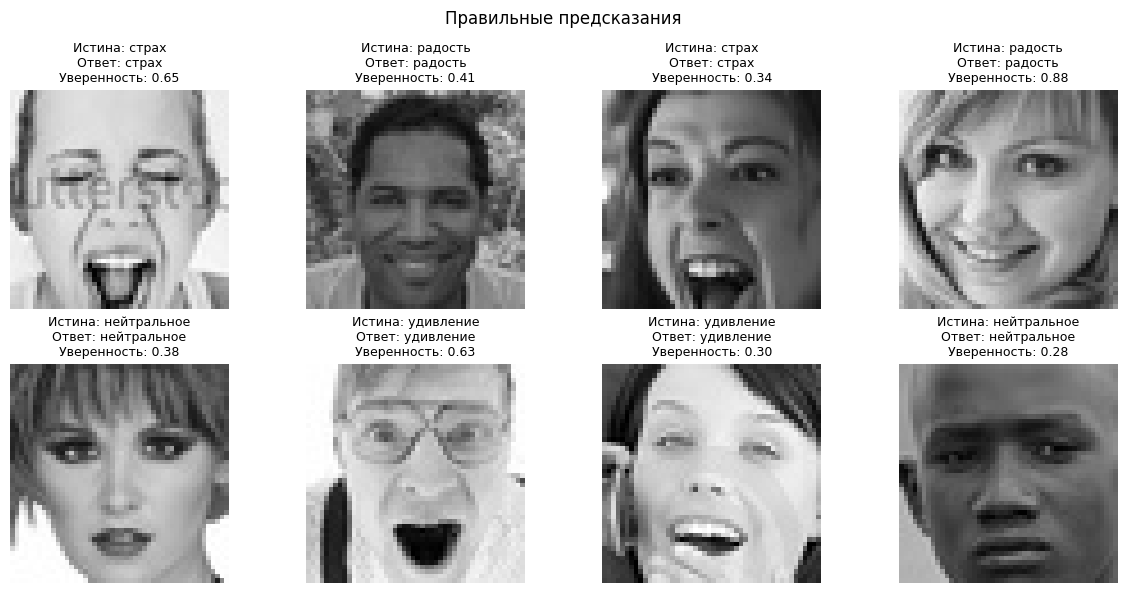

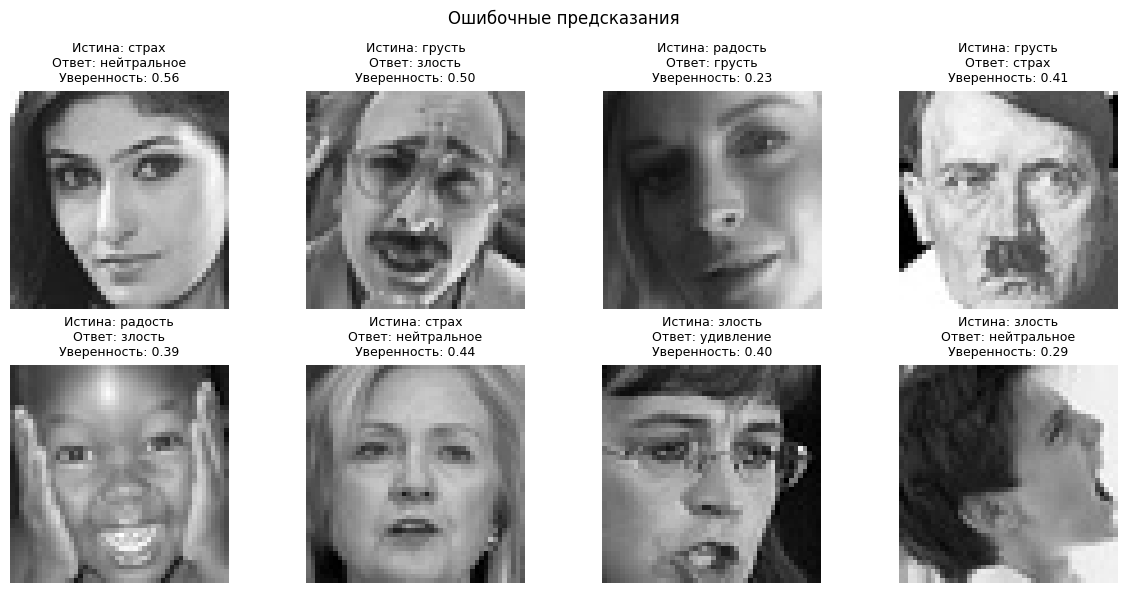

In [7]:
results = pd.DataFrame({
    'image_id': val_ids.astype(str),
    'true_label': y_val,
    'predicted_label': val_predictions,
    'true_emotion': [EMOTIONS[i] for i in y_val],
    'predicted_emotion': [EMOTIONS[i] for i in val_predictions],
    'confidence': val_probabilities.max(axis=1),
    'correct': y_val == val_predictions
})

results.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)

correct_idx = np.flatnonzero(y_val == val_predictions)
wrong_idx = np.flatnonzero(y_val != val_predictions)

print('Верных примеров:', len(correct_idx), '| Ошибочных:', len(wrong_idx))


def show_examples(indices, title, limit=8):
    indices = indices[:limit]

    if len(indices) == 0:
        print('Нет примеров для показа:', title)
        return

    cols = 4
    rows = int(np.ceil(len(indices) / cols))

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(12, 3 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis('off')

    for ax, idx in zip(axes, indices):
        ax.imshow(X_val[idx], cmap='gray', vmin=0, vmax=1)

        ax.set_title(
            f"Истина: {EMOTION_RU[EMOTIONS[y_val[idx]]]}\n"
            f"Ответ: {EMOTION_RU[EMOTIONS[val_predictions[idx]]]}\n"
            f"Уверенность: {val_probabilities[idx].max():.2f}",
            fontsize=9
        )

        ax.axis('off')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_examples(correct_idx, 'Правильные предсказания')
show_examples(wrong_idx, 'Ошибочные предсказания')

## 7. Сохранение модели и повторный запуск

Сохраняются модель Keras, конфигурация классов и параметров, метрики, матрица ошибок и CSV с предсказаниями. После обучения проверяем повторную загрузку модели и предсказание на одном validation-примере.

In [8]:
MODEL_PATH = MODEL_DIR / 'model.keras'
model.save(MODEL_PATH)

config = {
    'model_name': 'FER-2013 baseline CNN',
    'input_shape': [48, 48, 1],
    'pixel_range': [0.0, 1.0],
    'class_names': EMOTIONS,
    'class_names_ru': [EMOTION_RU[e] for e in EMOTIONS],
    'seed': SEED,
    'optimizer': 'Adam',
    'learning_rate': 0.001,
    'batch_size': 64,
    'max_epochs': 20,
    'early_stopping': {'monitor': 'val_loss', 'patience': 4, 'restore_best_weights': True},
    'augmentation': ['horizontal_flip', 'rotation_0.04', 'translation_0.04'],
    'training_data': 'prepared_fer2013/train.npz',
    'validation_data': 'prepared_fer2013/val.npz',
    'test_used': False
}
(MODEL_DIR / 'config.json').write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8'
)

loaded_model = tf.keras.models.load_model(MODEL_PATH)
sample_prob = loaded_model.predict(X_val_ready[:1], verbose=0)[0]
sample_class = int(np.argmax(sample_prob))
print('Проверка сохранённой модели:')
print('Истинный класс:', EMOTION_RU[EMOTIONS[int(y_val[0])]])
print('Предсказание:', EMOTION_RU[EMOTIONS[sample_class]])
print('Уверенность:', round(float(sample_prob[sample_class]), 4))
print('Сохранено в:', OUTPUT_DIR)
print('Файлы:', [str(p.relative_to(OUTPUT_DIR)) for p in OUTPUT_DIR.rglob('*') if p.is_file()])

Проверка сохранённой модели:
Истинный класс: страх
Предсказание: страх
Уверенность: 0.6546
Сохранено в: /kaggle/working/week3_output
Файлы: ['validation_predictions.csv', 'metrics.json', 'confusion_matrix.png', 'baseline_model/config.json', 'baseline_model/model.keras']


## 8. Вывод

После выполнения ноутбука заполните вывод фактическими значениями из таблицы метрик и кратко опишите наиболее частые ошибки по матрице ошибок. Не вписывайте заранее ожидаемые значения: метрики зависят от версии данных, доступного оборудования и фактического запуска.

**Ограничения:** FER-2013 содержит небольшие изображения 48×48 и шумную разметку. Классификация выражения лица не равна определению реального эмоционального состояния или удовлетворённости человека. Нельзя делать выводы о конкретном покупателе; результаты допустимо рассматривать только как исследовательские агрегаты с учётом согласия, приватности и требований законодательства.

**Что сдаётся:** этот ноутбук с выполненными ячейками, описание baseline, метрики validation, матрица ошибок, примеры правильных/ошибочных предсказаний, сохранённая модель и инструкция запуска. Test на третьей неделе не использовался.